# Lab 3: K-Means and K-Medoids Clustering on the Wine Dataset

**Student:** Rajasekhar Reddy Kayyam  
**Course:** MSCS 634 – Advanced Big Data & Data Mining  
**University:** University of the Cumberlands  
**Lab:** 3 – Clustering and Evaluation

## Objective
Compare K-Means and K-Medoids clustering on standardized Wine Dataset features, using Silhouette Score, Adjusted Rand Index (ARI), and side-by-side PCA scatter plots.

## Step 1 – Load and explore the dataset
The Wine Dataset contains 178 observations, 13 numeric chemical measurements, and 3 reference wine classes. **Class labels are used only for evaluation**, not for clustering.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_wine
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score, pairwise_distances
from sklearn.decomposition import PCA

wine = load_wine()
X = wine.data
y = wine.target
features = wine.feature_names
print('Dataset shape:', X.shape)
print('Features:', features)
print('Class distribution:')
print(pd.Series(y).value_counts().sort_index().rename_axis('class').to_string())
display(pd.DataFrame(X, columns=features).head())
print('Missing values:', np.isnan(X).sum())

Dataset shape: (178, 13)
Features: ['alcohol', 'malic_acid', 'ash', 'alcalinity_of_ash', 'magnesium', 'total_phenols', 'flavanoids', 'nonflavanoid_phenols', 'proanthocyanins', 'color_intensity', 'hue', 'od280/od315_of_diluted_wines', 'proline']
Class distribution:
class
0    59
1    71
2    48


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0


Missing values: 0


### Standardize using z-scores
For each feature, subtract its training-sample mean and divide by its standard deviation. This is unsupervised analysis of the full dataset, so no train/test split is required.

In [2]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
print('Feature means (rounded):', np.round(X_scaled.mean(axis=0), 3))
print('Feature standard deviations (rounded):', np.round(X_scaled.std(axis=0), 3))

Feature means (rounded): [ 0.  0. -0. -0. -0. -0.  0. -0. -0. -0.  0.  0. -0.]
Feature standard deviations (rounded): [1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]


## Step 2 – K-Means clustering (k = 3)
K-Means minimizes squared Euclidean distances from observations to their cluster centroids. Fixing `random_state` and specifying `n_init` makes the results reproducible.

In [3]:
kmeans = KMeans(n_clusters=3, random_state=42, n_init=20)
km_labels = kmeans.fit_predict(X_scaled)
km_sil = silhouette_score(X_scaled, km_labels)
km_ari = adjusted_rand_score(y, km_labels)
print('K-Means Silhouette Score:', round(km_sil, 4))
print('K-Means Adjusted Rand Index:', round(km_ari, 4))
print('Cluster sizes:', np.bincount(km_labels))

K-Means Silhouette Score: 0.2849
K-Means Adjusted Rand Index: 0.8975
Cluster sizes: [65 51 62]


## Step 3 – K-Medoids clustering (k = 3)
K-Medoids uses **actual observations** as representatives (medoids), unlike K-Means centroids. The code below implements the PAM swap optimization directly with NumPy, avoiding optional `scikit-learn-extra` compatibility issues. It uses Euclidean distances and multiple seeded random starts, retaining the lowest-cost result.

In [4]:
def pam_kmedoids(X, k=3, random_state=42, n_init=10, max_iter=100):
    D = pairwise_distances(X, metric='euclidean')
    rng = np.random.default_rng(random_state)
    n = len(X)
    best = None
    for run in range(n_init):
        medoids = rng.choice(n, size=k, replace=False)
        for iteration in range(max_iter):
            costs = D[:, medoids].min(axis=1)
            current_cost = costs.sum()
            best_swap = None
            best_cost = current_cost
            other_indices = np.setdiff1d(np.arange(n), medoids)
            for position in range(k):
                for candidate in other_indices:
                    trial = medoids.copy()
                    trial[position] = candidate
                    trial_cost = D[:, trial].min(axis=1).sum()
                    if trial_cost < best_cost - 1e-10:
                        best_cost = trial_cost
                        best_swap = (position, candidate)
            if best_swap is None:
                break
            medoids[best_swap[0]] = best_swap[1]
        labels = D[:, medoids].argmin(axis=1)
        total_cost = D[np.arange(n), medoids[labels]].sum()
        if best is None or total_cost < best['cost']:
            best = {'medoid_indices': medoids.copy(), 'labels': labels.copy(), 'cost': total_cost, 'iterations': iteration + 1}
    return best

pam = pam_kmedoids(X_scaled, k=3, random_state=42, n_init=10)
medoid_indices = pam['medoid_indices']
medoid_points = X_scaled[medoid_indices]
med_labels = pam['labels']
med_sil = silhouette_score(X_scaled, med_labels)
med_ari = adjusted_rand_score(y, med_labels)
print('K-Medoids Silhouette Score:', round(med_sil, 4))
print('K-Medoids Adjusted Rand Index:', round(med_ari, 4))
print('Medoid row indices:', medoid_indices)
print('Cluster sizes:', np.bincount(med_labels))

K-Medoids Silhouette Score: 0.2676
K-Medoids Adjusted Rand Index: 0.7411
Medoid row indices: [106  35 148]
Cluster sizes: [55 74 49]


## Step 4 – Compare evaluation metrics
**Silhouette Score** measures within-cluster cohesion versus separation (larger is better; range −1 to 1). **ARI** compares assignments with true wine classes, corrected for chance (1 is perfect agreement). Cluster IDs are arbitrary; ARI does not require matching label numbers.

In [5]:
results = pd.DataFrame({
    'Algorithm': ['K-Means', 'K-Medoids (PAM)'],
    'Silhouette Score': [km_sil, med_sil],
    'Adjusted Rand Index': [km_ari, med_ari]
})
display(results.round(4))
print('Better-defined clusters (Silhouette):', results.loc[results['Silhouette Score'].idxmax(), 'Algorithm'])
print('Closer to true classes (ARI):', results.loc[results['Adjusted Rand Index'].idxmax(), 'Algorithm'])

,Algorithm,Silhouette Score,Adjusted Rand Index
0,K-Means,0.2849,0.8975
1,K-Medoids (PAM),0.2676,0.7411


Better-defined clusters (Silhouette): K-Means
Closer to true classes (ARI): K-Means


### PCA visualization
PCA projects standardized 13-dimensional observations onto two components for plotting. **All clustering and evaluation metrics above use the full 13-dimensional standardized data**, not the 2D projection. Centroids and medoids are projected using the same fitted PCA transformation.

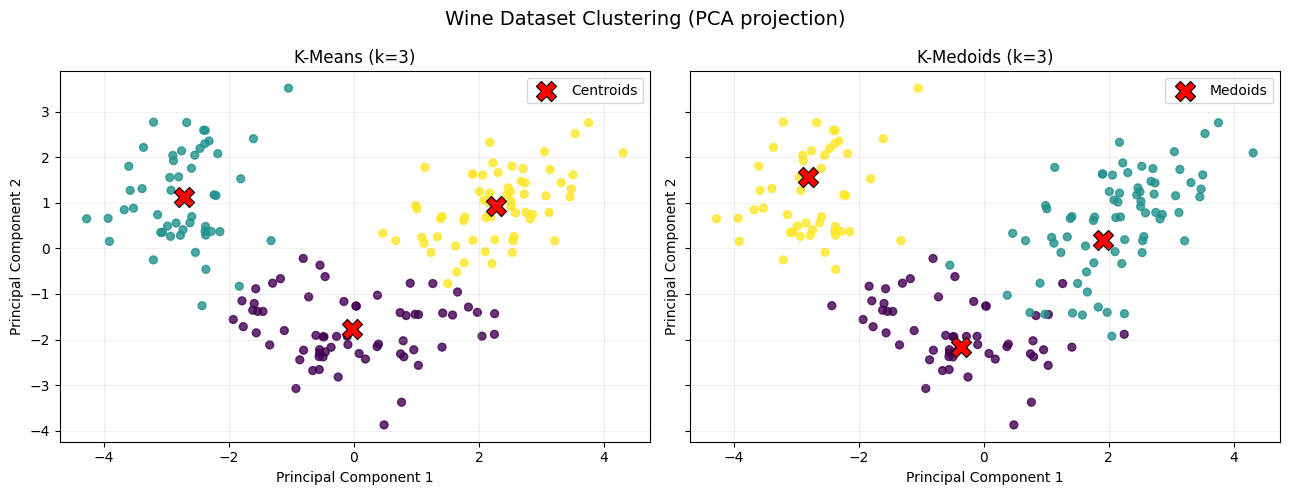

Variance explained by PC1 and PC2: [0.362  0.1921]


In [6]:
pca = PCA(n_components=2)
X_2d = pca.fit_transform(X_scaled)
centroids_2d = pca.transform(kmeans.cluster_centers_)
medoids_2d = pca.transform(medoid_points)
fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharex=True, sharey=True)
for ax, labels, centers, title in [
    (axes[0], km_labels, centroids_2d, 'K-Means (k=3)'),
    (axes[1], med_labels, medoids_2d, 'K-Medoids (k=3)')
]:
    ax.scatter(X_2d[:, 0], X_2d[:, 1], c=labels, cmap='viridis', s=32, alpha=0.8)
    ax.scatter(centers[:, 0], centers[:, 1], c='red', marker='X', s=210,
               edgecolor='black', linewidth=0.8, label='Centroids' if 'Means' in title else 'Medoids')
    ax.set_title(title)
    ax.set_xlabel('Principal Component 1')
    ax.set_ylabel('Principal Component 2')
    ax.legend()
    ax.grid(alpha=0.2)
fig.suptitle('Wine Dataset Clustering (PCA projection)', fontsize=14)
fig.tight_layout()
fig.savefig('clustering_comparison.png', dpi=180, bbox_inches='tight')
plt.show()
print('Variance explained by PC1 and PC2:', np.round(pca.explained_variance_ratio_, 4))

## Discussion and interpretation
Run the cells above before finalizing your written conclusions. The output table identifies the higher Silhouette Score and ARI. A higher Silhouette Score indicates more compact/separated groups; a higher ARI indicates better alignment with the known wine classes. These can favor different methods.

**Cluster shapes and positions:** Compare the PCA plots for overlap, separation, and whether projected centroids/medoids lie near dense areas. PCA is a 2D approximation and may hide structure from the full feature space.

**When to prefer K-Means:** It is usually faster and scales well for large numeric datasets with compact, roughly spherical clusters. Its means can be sensitive to outliers.

**When to prefer K-Medoids:** Its representatives are actual data records, making them more interpretable and often more robust to extreme observations. PAM is computationally more expensive because it evaluates many candidate swaps.

**Challenges/decisions:** Feature scaling is essential because Wine attributes have different ranges. We use a reproducible PAM implementation to avoid optional-package installation issues. The labels are held out from clustering and used only to calculate ARI. Multiple PAM starts reduce sensitivity to initialization, but do not guarantee a global optimum.

## References
Pedregosa, F., et al. (2011). Scikit-learn: Machine learning in Python. *Journal of Machine Learning Research, 12*, 2825–2830. https://jmlr.org/papers/v12/pedregosa11a.html

Rousseeuw, P. J. (1987). Silhouettes: A graphical aid to the interpretation and validation of cluster analysis. *Journal of Computational and Applied Mathematics, 20*, 53–65. https://doi.org/10.1016/0377-0427(87)90125-7